In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import json

Plots

In [2]:
def draw_plots(path):
    with open(path, "r") as f:
        dic = json.load(f)
    history = dic["history"]
    batch_hist = [row for row in history if "avg_vloss" not in row]
    epoch_hist = [row for row in history if "avg_vloss" in row]
    bdf = pd.DataFrame(batch_hist)
    edf = pd.DataFrame(epoch_hist)
    # fractional epoch: 2.5 == halfway through epoch 2
    bdf["progress"] = bdf["epoch"] + bdf["batch_percentage"]
    # epoch-level rows are logged at the *end* of the epoch
    edf["progress"] = edf["epoch"] + (edf["batch_idx"]/ 137476)
    has_bleu = "bleu_calculations_val" in edf

    train_c, val_c, time_c = "#2a78d6", "#eb6834", "#1baf7a"
    if has_bleu:
        fig, (ax_loss, ax_time, ax_gap,ax_non_smooth,ax_bleu) = plt.subplots(
                    5, 1, figsize=(12, 12), sharex=True, constrained_layout=True
            )
    else:
        fig, (ax_loss, ax_time, ax_gap,ax_non_smooth) = plt.subplots(
            4, 1, figsize=(12, 12), sharex=True, constrained_layout=True
        )
    fig.suptitle(f"Training run: {path}", fontsize=13)

    # 1) batch loss with epoch-level averages overlaid on the same timeline
    ax_loss.plot(bdf["progress"], bdf["batch_loss"], color=train_c, lw=1,
                 alpha=0.6, label="train loss (per batch)")
    # if "avg_loss" in edf:
    #     ax_loss.plot(edf["progress"], edf["avg_loss"], color=train_c, lw=2,
    #                 marker="o", ms=5, label="train loss (epoch avg)")
    ax_loss.plot(edf["progress"], edf["avg_vloss"], color=val_c, lw=2,
                 marker="o", ms=5, label="val loss (epoch avg)")
    ax_loss.set_yscale("log")
    ax_loss.yaxis.set_major_formatter(ScalarFormatter())
    ax_loss.yaxis.set_minor_formatter(ScalarFormatter())
    ax_loss.set_ylabel("cross-entropy loss (log scale)")
    ax_loss.set_title("Loss")
    ax_loss.legend(loc="upper right")

    # 2) per-batch step time
    ax_time.plot(bdf["progress"], bdf["tokens/sec"], color=time_c, lw=1)
    ax_time.set_ylabel("tokens/sec")
    ax_time.set_title("tokens/sec")

    # 3) train/val gap per epoch
    # if "avg_loss" in edf:
    #     ax_gap.plot(edf["progress"], edf["avg_vloss"] - edf["avg_loss"],
    #                 color=val_c, lw=2, marker="o", ms=5)
    ax_gap.axhline(0, color="0.6", lw=1, ls="--")
    ax_gap.set_ylabel("val loss − train loss")
    ax_gap.set_title("Generalization gap (positive = val worse than train)")
    ax_gap.set_xlabel("epoch")

    # 4) batch non smoothed CE with epoch-level averages overlaid on the same timeline
    if "non_smoothed_loss_fn_val" in edf:
        # ax_non_smooth.plot(edf["progress"], edf["non_smoothed_loss_fn"], color=train_c, lw=2,
        #             marker="o", ms=5, label="train non smoothed CE (epoch avg)")
        ax_non_smooth.plot(edf["progress"], edf["non_smoothed_loss_fn_val"], color=val_c, lw=2,
                    marker="o", ms=5, label="val non smoothed CE (epoch avg)")
        ax_non_smooth.set_yscale("log")
        ax_non_smooth.yaxis.set_major_formatter(ScalarFormatter())
        ax_non_smooth.yaxis.set_minor_formatter(ScalarFormatter())
        ax_non_smooth.set_ylabel("cross-entropy loss (log scale)")
        ax_non_smooth.set_title("Non Smoothed Loss")
        ax_non_smooth.legend(loc="upper right")

    
    if has_bleu:
        # ax_bleu.plot(edf["progress"], edf["bleu_calculations_val"], color=train_c, lw=2,
        #             marker="o", ms=5, label="train non smoothed CE (epoch avg)")
        filtered_bleu = edf[edf["bleu_calculations_val"] > 0]
        ax_bleu.plot(filtered_bleu["progress"], filtered_bleu["bleu_calculations_val"], color=val_c, lw=2,
                    marker="o", ms=5, label="val BLEU")
        ax_bleu.yaxis.set_major_formatter(ScalarFormatter())
        ax_bleu.yaxis.set_minor_formatter(ScalarFormatter())
        ax_bleu.set_ylabel("val bleu")
        ax_bleu.set_title("BLEU")
        ax_bleu.legend(loc="upper right")

    for ax in (ax_loss, ax_time, ax_gap,ax_non_smooth):
        ax.grid(True, color="0.9", lw=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    ax_gap.set_xlim(0, edf["progress"].max())
    ax_gap.set_xticks(range(0, int(edf["progress"].max()) + 1))

    plt.show()
    return bdf, edf, batch_hist

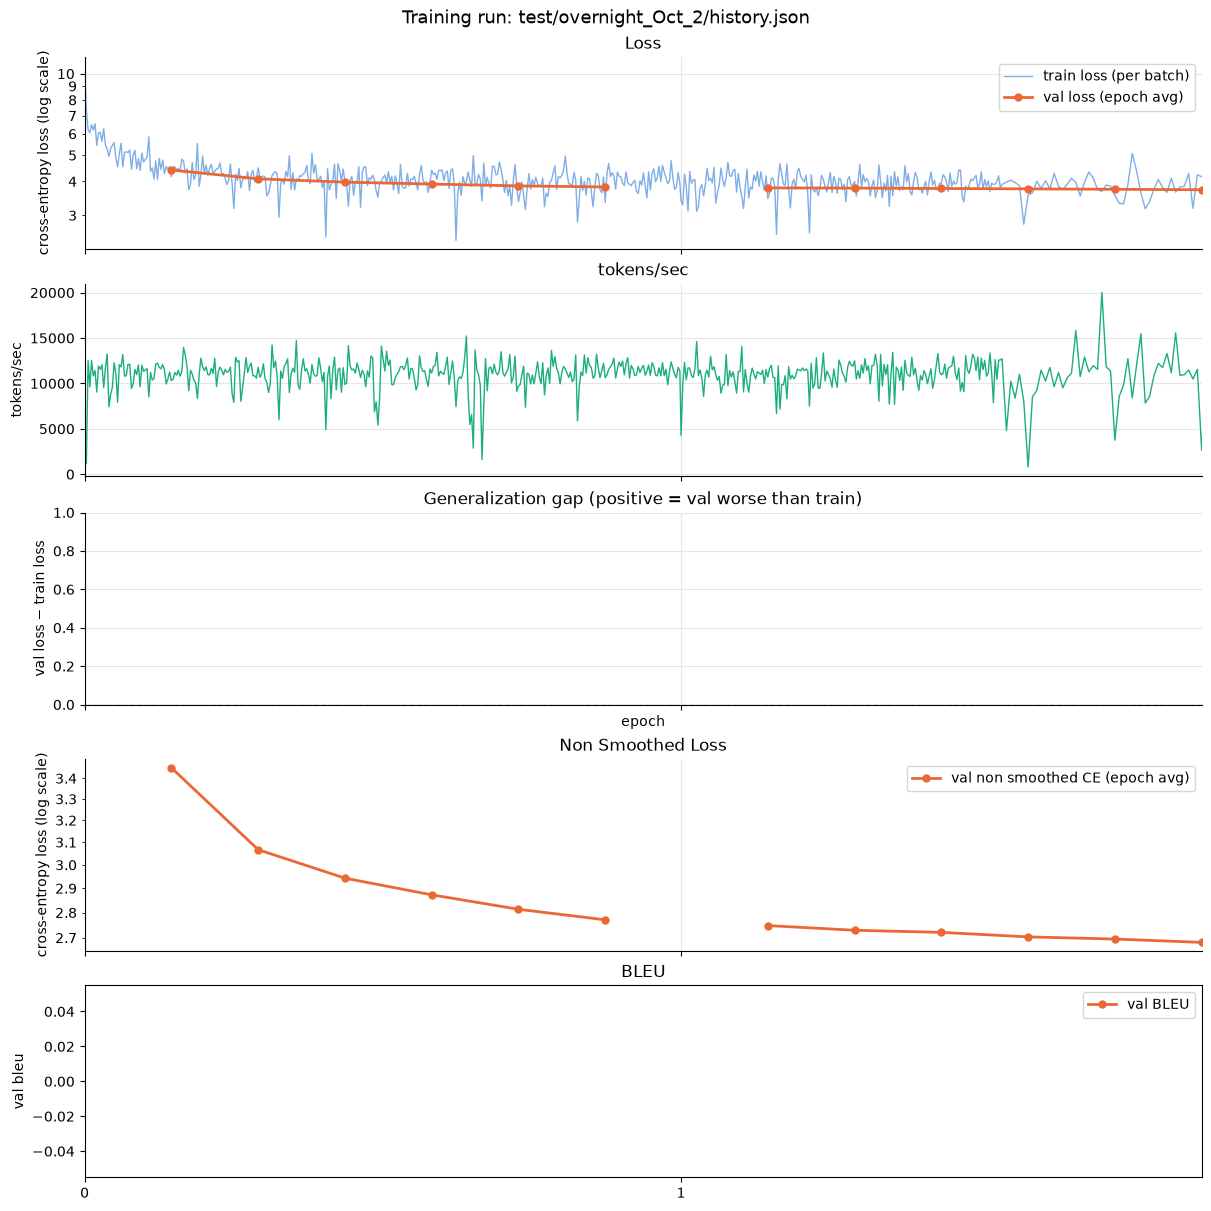

In [3]:
bdf_2,edf_2,batch_hist_2 = draw_plots("test/overnight_Oct_2/history.json")

In [25]:
edf_27.head()

,avg_vloss,epoch,batch_idx,non_smoothed_loss_fn_val,bleu_calculations_val,progress
0,4.408630,0,19999,3.452466,0.0,1
1,4.091791,0,39999,3.066844,0.0,1
2,3.978325,0,59999,2.942980,0.0,1
3,3.913265,0,79999,2.872954,0.0,1


In [ ]:
bdf_9,edf_9,batch_hist_9 = draw_plots("test/overnight_Sep_9/history.json")

In [ ]:
bdf_20_v2,edf_20_v2,batch_hist_20_v2 = draw_plots("test/overnight_Sep_20_v2/history.json")

In [ ]:
edf_20_v2.tail()

In [ ]:
def draw_multiple_plots(paths,has_bleu=False):
    # one color per run; within a run, train = solid, val = dashed
    run_colors = plt.get_cmap("tab10").colors
    if has_bleu:
        fig, (ax_loss, ax_non_smooth, ax_bleu) = plt.subplots(
                    3, 1, figsize=(12, 10), sharex=True, constrained_layout=True
            )
        axes = (ax_loss, ax_non_smooth, ax_bleu)
    else:
        fig, (ax_loss, ax_non_smooth) = plt.subplots(
            2, 1, figsize=(12, 8), sharex=True, constrained_layout=True
        )
        axes = (ax_loss, ax_non_smooth)
    fig.suptitle(f"Training runs", fontsize=13)
    max_progress = 0
    for i, path in enumerate(paths):
        color = run_colors[i % len(run_colors)]
        run_name = path.split("/")[-2] if "/" in path else path
        with open(path, "r") as f:
            dic = json.load(f)
        history = dic["history"]
        batch_hist = [row for row in history if "batch_idx" in row]
        epoch_hist = [row for row in history if "batch_idx" not in row]
        bdf = pd.DataFrame(batch_hist)
        edf = pd.DataFrame(epoch_hist)
        # fractional epoch: 2.5 == halfway through epoch 2
        bdf["progress"] = bdf["epoch"] + bdf["batch_percentage"]
        # epoch-level rows are logged at the *end* of the epoch
        edf["progress"] = edf["epoch"] + 1
        max_progress = max(max_progress, edf["progress"].max())

        # 1) batch loss with epoch-level averages overlaid on the same timeline
        ax_loss.plot(bdf["progress"], bdf["batch_loss"], color=color, lw=1,
                    alpha=0.25)
        ax_loss.plot(edf["progress"], edf["avg_loss"], color=color, lw=2,
                    marker="o", ms=5, label=f"{run_name} train")
        ax_loss.plot(edf["progress"], edf["avg_vloss"], color=color, lw=2, ls="--",
                    marker="s", ms=5, label=f"{run_name} val")

        # 2) non smoothed CE epoch-level averages
        if "non_smoothed_loss_fn_val" in edf:
            ax_non_smooth.plot(edf["progress"], edf["non_smoothed_loss_fn"], color=color, lw=2,
                        marker="o", ms=5, label=f"{run_name} train")
            ax_non_smooth.plot(edf["progress"], edf["non_smoothed_loss_fn_val"], color=color, lw=2, ls="--",
                        marker="s", ms=5, label=f"{run_name} val")

        # 3) val BLEU (only epochs where it was computed)
        if "bleu_calculations_val" in edf and has_bleu:
            filtered_bleu = edf[edf["bleu_calculations_val"] > 0]
            ax_bleu.plot(filtered_bleu["progress"], filtered_bleu["bleu_calculations_val"], color=color, lw=2,
                        marker="o", ms=5, label=f"{run_name} val")

    ax_loss.set_yscale("log")
    ax_loss.yaxis.set_major_formatter(ScalarFormatter())
    ax_loss.yaxis.set_minor_formatter(ScalarFormatter())
    ax_loss.set_ylabel("cross-entropy loss (log scale)")
    ax_loss.set_title("Loss (thin = per batch, solid = train epoch avg, dashed = val epoch avg)")

    ax_non_smooth.set_yscale("log")
    ax_non_smooth.yaxis.set_major_formatter(ScalarFormatter())
    ax_non_smooth.yaxis.set_minor_formatter(ScalarFormatter())
    ax_non_smooth.set_ylabel("cross-entropy loss (log scale)")
    ax_non_smooth.set_title("Non Smoothed Loss")

    if has_bleu:
        ax_bleu.set_ylabel("val bleu")
        ax_bleu.set_title("BLEU")

    for ax in axes:
        ax.legend(loc="upper right", fontsize=8)
        ax.grid(True, color="0.9", lw=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[-1].set_xlabel("epoch")
    axes[-1].set_xlim(0, max_progress)
    axes[-1].set_xticks(range(0, int(max_progress) + 1))

    plt.show()

In [ ]:
draw_multiple_plots([
    "test/overnight_Sep_20_v2/history.json",
    "test/overnight_Sep_9/history.json",
    # "test/overnight_Sep_20/history.json"
    # "test/overnight_Sep_19_v2/history.json",
    # "test/overnight_Sep_1/history.json",
])

Decoding 

In [4]:
import sentencepiece
import torch
from torch.distributions import Categorical
from torchmetrics.text import BLEUScore,SacreBLEUScore

In [5]:
import importlib
import train
importlib.reload(train)
from train import DEVICE, config, load_best_model, sp_bpe

In [6]:
model, _, history = load_best_model(latest=True)



num_parameters: 63,045,632 - num_non_embedding_params: 44,101,632
2026-10-07 03:07:19.691170: loss_fn loaded
2026-10-07 03:07:19.691310: loading best pre saved
best model path not found. Loading from: ./test/overnight_Oct_2/model_2_keyboard_intrrupt.pt
2026-10-07 03:07:19.799128: Starting from pre saved with: start_epoch: 2, best_val_loss: 3.7317, last_epoch_vloss: 3.73, non_improve_cnt: 0.00


In [7]:
sp_bpe = sentencepiece.SentencePieceProcessor()
sp_bpe.load(f"tokenizers/{config["tokenizer_source"]}/bpe.model")
sacreblue_metric = SacreBLEUScore(lowercase=True)
blue_metric = BLEUScore()

In [16]:
english_orig_translation = "The human brain processes visual information much faster than we previously assumed in science."
german_text = "Das menschliche Gehirn verarbeitet visuelle Informationen viel schneller, als wir bisher in der Wissenschaft angenommen haben."

german_list_enc = sp_bpe.encode_as_ids(german_text, add_bos=True, add_eos=True)
german_encoding = torch.tensor([german_list_enc]).to(DEVICE)

english_encoding = [sp_bpe.bos_id()]

i = 0
model.eval()
with torch.no_grad():
    while i < 20:
        logits = model.forward(german_encoding,torch.tensor([english_encoding]).to(DEVICE)) # B,Sy,VS
        dist = Categorical(logits=logits[0,-1,:])

        new_enc = dist.sample().item()
        english_encoding.append(new_enc)
        print(f"debug: new encoding: '{sp_bpe.decode_ids(english_encoding)}'")
        if new_enc == sp_bpe.eos_id():
            print("debug: reached EOS")
            break 
        i+=1
sacre_score = sacreblue_metric([sp_bpe.decode_ids(english_encoding)], [[english_orig_translation]])
score = blue_metric([sp_bpe.decode_ids(english_encoding)], [[english_orig_translation]])
print(f"SacreBLEU Score: {sacre_score}")
print(f"BLEU Score: {score}")

debug: new encoding: 'The'
debug: new encoding: 'The human'
debug: new encoding: 'The human brain'
debug: new encoding: 'The human brain will'
debug: new encoding: 'The human brain will getting'
debug: new encoding: 'The human brain will getting visual'
debug: new encoding: 'The human brain will getting visual information'
debug: new encoding: 'The human brain will getting visual information much'
debug: new encoding: 'The human brain will getting visual information much faster'
debug: new encoding: 'The human brain will getting visual information much faster than'
debug: new encoding: 'The human brain will getting visual information much faster than we'
debug: new encoding: 'The human brain will getting visual information much faster than we have'
debug: new encoding: 'The human brain will getting visual information much faster than we have in'
debug: new encoding: 'The human brain will getting visual information much faster than we have in science'
debug: new encoding: 'The human bra

Batch calculations and comparing with original paper

In [ ]:
from train import load_data, lr_update_fn
import torch

In [ ]:
config["mega_batch_size"]

In [ ]:
train_loader, val_loader = load_data()

In [ ]:
total_x = 0
total_y = 0
x_len=0
y_len=0

pad_tokens = 0
for X,Y in train_loader: # B,Sy
    cur_x = torch.sum(X != config["pad_token"])
    cur_y = torch.sum(Y != config["pad_token"])
    pad_tokens += X.shape[0] * (X.shape[1] + Y.shape[1]) - cur_x - cur_y
    total_x+=cur_x
    total_y+=cur_y

    x_len+=X.shape[1]
    y_len+=Y.shape[1]

In [ ]:
print(f"total_x: {total_x.item():,}")
print(f"total_y: {total_y.item():,}")
print(f"total_pad_tokens: {pad_tokens.item():,}")

print("per step: ")
print(f"total_x: {total_x / len(train_loader):,.2f}")
print(f"total_y: {total_y / len(train_loader):,.2f}")
print(f"pad_tokens: {pad_tokens / len(train_loader) / 2:,.2f}")
print(f"X_len: {x_len / len(train_loader):.2f}")
print(f"Y_len: {y_len / len(train_loader):.2f}")

In [ ]:
batches_per_epoch_me = 3221 # from logs/output_logs_overnight_Sep_5_2.txt
num_epochs_me = 15
sent_len_me = (x_len + y_len)/(2*len(train_loader))
sent_len_them = sent_len_me #??
print(f"tokens seen total: {100_000 * 25_000:,} - {(total_x) * num_epochs_me:,}")
print(f"tokens/batch:      {25_000:,} - {(total_x + total_y)/len(train_loader):,.0f}")
print(f"tokens/epoch:      {4_500_000 * sent_len_them:,.0f} - {total_x + total_y:,}") # assuming they have the same sentence length as us
print(f"batches/epoch:     {(4_500_000 * sent_len_them / 25_000):,.0f} - {batches_per_epoch_me:,}") # batches_t * tokens/epoch / tokens_t
print(f"epochs:            {100_000 / ((4_500_000 * sent_len_them / 25_000)):.1f} - {num_epochs_me}")
print(f"batches:           {100_000:,} - {batches_per_epoch_me * num_epochs_me:,.2f}")

took back: 

- higher tokens/batch than paper -> less gradient noise. Hence better. 
- batches/epoch is half -> Noam LR is still warming up at the start
- total batches is third -> Noam LR is not fully calmed down yet at the end -> lower warmup_steps. 
- 

Calculating BLEU

In [17]:
import importlib
import train
importlib.reload(train)
from train import calculate_bleu, load_best_model, load_data

In [18]:
train_loader, val_loader, train_token_count = load_data(sp_bpe)
print(f"{train_token_count:,}")
del train_loader

2026-10-07 03:08:42.147541: encoding train started
2026-10-07 03:08:42.148251 cache found
2026-10-07 03:08:44.070783: encoding val started
2026-10-07 03:08:44.072177 cache found
2026-10-07 03:08:44.074692: # train size: #Tokens: X: 140,258,426 Y: 133,374,357 #Sentences: 4,399,220, num_dropped: 0
2026-10-07 03:08:44.074723: # val size: #Tokens: X: 85,219 Y: 80,564 #Sentences: 2,996, num_dropped: 0
2026-10-07 03:08:44.074756: batches/epoch: 137,476. LR peak: 0.0008068715304598784
140,258,426


/Users/mohammadaminsedaghat/Desktop/attention/train.py:192: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  self.X = torch.from_numpy(X)


In [18]:
model, _, history = load_best_model()



num_parameters: 63,045,632 - num_non_embedding_params: 44,101,632
2026-10-03 18:57:56.725196: loss_fn loaded
2026-10-03 18:57:56.725209: loading best pre saved
best model path not found. Loading from: ./test/overnight_Oct_2/model_0_keyboard_intrrupt.pt
2026-10-03 18:57:56.858673: Starting from pre saved with: start_epoch: 0, best_val_loss: inf, last_epoch_vloss: inf, non_improve_cnt: 0.00


In [ ]:
gen = calculate_bleu(val_loader,model,sp_bpe,return_translations=False) 
# sep_20_v2: 28.66
# sep_9: 30.81
# oct 2: 18.74

2026-10-07 03:08:55.581055 started calculating bleu


In [8]:
sp_bpe.vocab_size()

37000